In [31]:
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

df = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')

print(f'Train: {train.shape}  |  Test: {test.shape}')
print(f'Missing values in train:\n{train.isnull().sum()[train.isnull().sum() > 0]}')
print(f'Missing values in test:\n{test.isnull().sum()[test.isnull().sum() > 0]}')

Train: (699635, 23)  |  Test: (299844, 22)
Missing values in train:
Arrival Delay in Minutes    292
dtype: int64
Missing values in test:
Arrival Delay in Minutes    130
dtype: int64


In [32]:
# If not installed, run in your notebook:
# %pip install lightgbm

import pandas as pd
import numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [33]:
# Separate features and target
X = df.drop(columns=["satisfaction"]).copy()
y = df["satisfaction"].copy()

numerical_cols = [
    "Age", "Flight Distance",
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location", "Food and drink",
    "Online boarding", "Seat comfort",
    "Inflight entertainment", "On-board service",
    "Leg room service", "Baggage handling",
    "Checkin service", "Cleanliness",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

categorical_cols = [
    "Gender", "Type of Travel", "Class", "Customer Type"
]

# Encode target labels
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

In [34]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

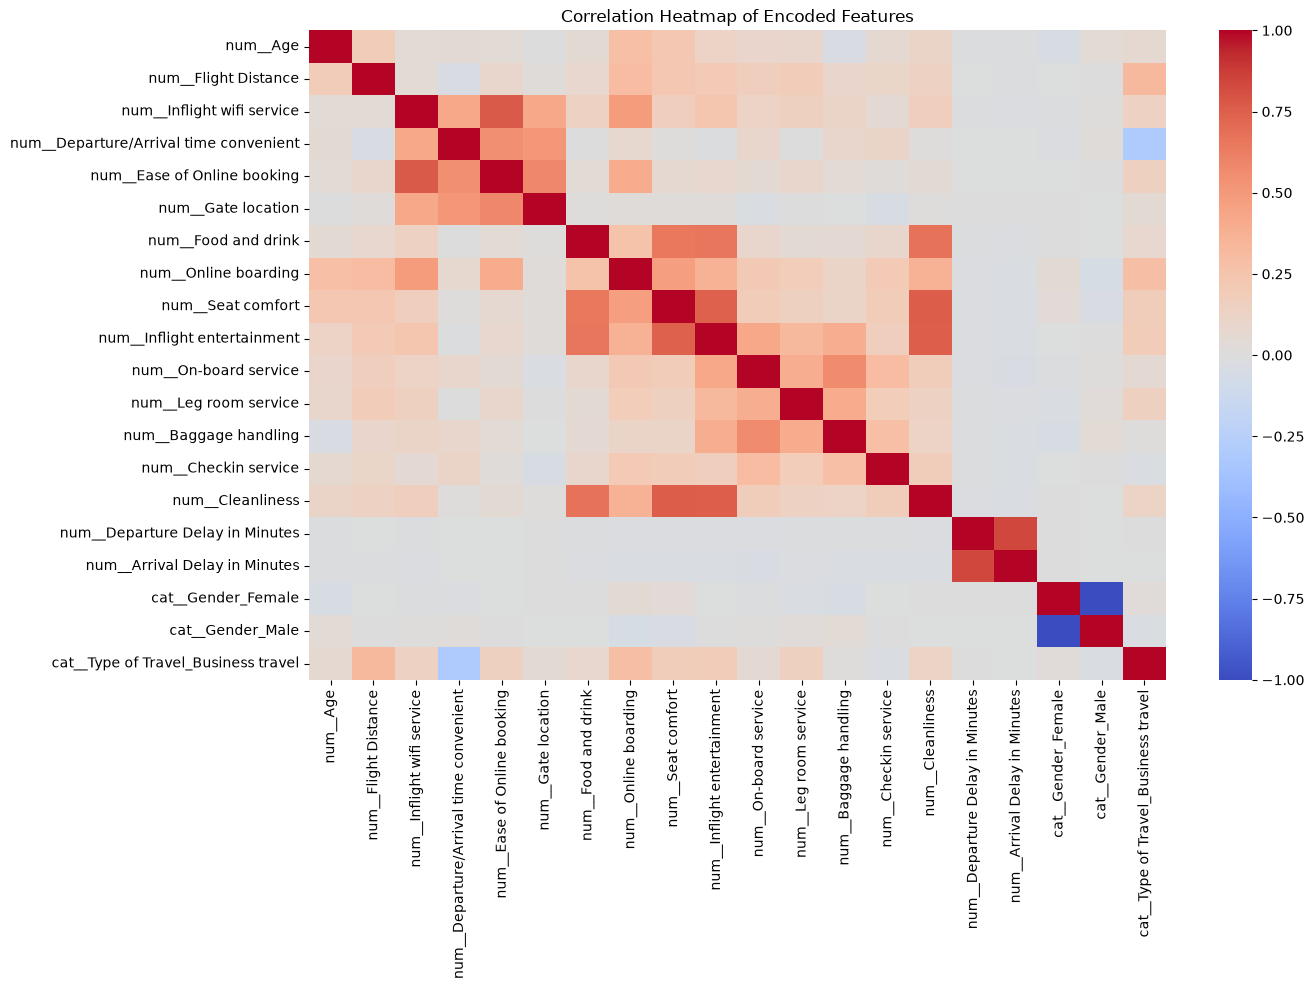

In [35]:
# Get transformed training features
X_train_encoded = (
    lgb_model.named_steps["preprocessor"]
    .transform(X_train)
)

# Get the encoded feature names
feature_names = (
    lgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Convert to DataFrame
X_encoded_df = pd.DataFrame(
    X_train_encoded.toarray()
    if hasattr(X_train_encoded, "toarray")
    else X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

# Correlation heatmap for a manageable subset
selected_features = X_encoded_df.columns[:20]

plt.figure(figsize=(14, 10))

sns.heatmap(
    X_encoded_df[selected_features].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Encoded Features")
plt.tight_layout()
plt.show()

In [36]:
lgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", lgb.LGBMClassifier(
        objective="binary",
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Train
lgb_model.fit(X_train, y_train)

print("Training completed!")

Training completed!


In [37]:
# Predict
y_pred = lgb_model.predict(X_test)
y_prob = lgb_model.predict_proba(X_test)[:, 1]

# Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(target_encoder.classes_)),
    target_names=[str(c) for c in target_encoder.classes_],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.9246035432761368

Classification Report:
              precision    recall  f1-score   support

       False       0.92      0.94      0.93     77859
        True       0.93      0.90      0.91     62068

    accuracy                           0.92    139927
   macro avg       0.92      0.92      0.92    139927
weighted avg       0.92      0.92      0.92    139927

Confusion Matrix:
[[73388  4471]
 [ 6079 55989]]
ROC-AUC: 0.9576608595093703


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get the trained LightGBM classifier
lgb_classifier = lgb_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = (
    lgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": lgb_classifier.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(20))

                                   Feature  Importance
1                     num__Flight Distance        4775
0                                 num__Age        3829
2               num__Inflight wifi service        1740
13                    num__Checkin service        1541
7                     num__Online boarding        1508
12                   num__Baggage handling        1370
11                   num__Leg room service        1274
5                       num__Gate location        1256
10                   num__On-board service        1247
8                        num__Seat comfort        1212
4              num__Ease of Online booking        1168
3   num__Departure/Arrival time convenient        1133
14                        num__Cleanliness        1026
9              num__Inflight entertainment        1022
16           num__Arrival Delay in Minutes        1010
15         num__Departure Delay in Minutes         980
6                      num__Food and drink         913
21        

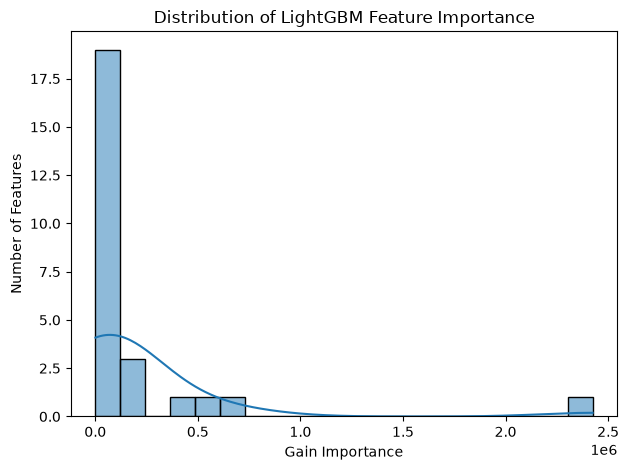

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get gain importance
lgb_classifier = lgb_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": (
        lgb_model.named_steps["preprocessor"]
        .get_feature_names_out()
    ),
    "Importance": lgb_classifier.booster_.feature_importance(
        importance_type="gain"
    )
})

# Plot histogram
sns.histplot(
    data=importance_df,
    x="Importance",
    bins=20,
    kde=True
)

plt.title("Distribution of LightGBM Feature Importance")
plt.xlabel("Gain Importance")
plt.ylabel("Number of Features")
plt.tight_layout()
plt.show()

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Trained LightGBM classifier
lgb_classifier = lgb_model.named_steps["classifier"]

# Feature names after preprocessing
encoded_names = (
    lgb_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Gain importance for each encoded feature
encoded_importance = lgb_classifier.booster_.feature_importance(
    importance_type="gain"
)

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": encoded_importance
})

# Map encoded names back to original column names
def get_original_feature(encoded_name):
    if encoded_name.startswith("num__"):
        return encoded_name.replace("num__", "", 1)

    if encoded_name.startswith("cat__"):
        name = encoded_name.replace("cat__", "", 1)

        # Match the original categorical column prefix
        for col in categorical_cols:
            if name.startswith(col + "_"):
                return col

    return encoded_name

importance_df["Original Feature"] = (
    importance_df["Feature"].apply(get_original_feature)
)

# Combine importance across one-hot encoded categories
original_importance = (
    importance_df.groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

print(original_importance)

                     Original Feature    Importance
18                    Online boarding  2.424337e+06
15              Inflight wifi service  7.159326e+05
20                     Type of Travel  5.473070e+05
4                               Class  4.999018e+05
6                       Customer Type  2.018061e+05
14             Inflight entertainment  1.882103e+05
19                       Seat comfort  1.276098e+05
2                    Baggage handling  1.169858e+05
3                     Checkin service  1.158276e+05
17                   On-board service  9.384170e+04
9              Ease of Online booking  8.854184e+04
0                                 Age  6.494897e+04
5                         Cleanliness  5.876985e+04
16                   Leg room service  4.361353e+04
10                    Flight Distance  4.036250e+04
12                      Gate location  3.627955e+04
8   Departure/Arrival time convenient  2.016008e+04
1            Arrival Delay in Minutes  1.030482e+04
11          

In [42]:
import pandas as pd

# Load new data without the target column
new_data = pd.read_csv("test.csv")

# Keep the ID column for the output
ids = new_data["id"].copy()

# Exclude ID from model input only if it wasn't used during training
X_new = new_data.drop(columns=["id", "satisfaction"], errors="ignore")

# Predict satisfaction
predictions = lgb_model.predict(X_new)
predicted_labels = target_encoder.inverse_transform(predictions)

# Predict probabilities
probabilities = lgb_model.predict_proba(X_new)

# Store IDs, predictions, and probabilities
results = pd.DataFrame({
    "id": ids,
    "Predicted_Satisfaction": predicted_labels,
    "Probability_Class_0": probabilities[:, 0],
    "Probability_Class_1": probabilities[:, 1]
})

print(results.head())

results[['id', 'Predicted_Satisfaction']].to_csv("lightgbm_predictions.csv", index=False)

       id  Predicted_Satisfaction  Probability_Class_0  Probability_Class_1
0  699635                   False             0.786624             0.213376
1  699636                    True             0.105505             0.894495
2  699637                    True             0.115667             0.884333
3  699638                   False             0.934456             0.065544
4  699639                   False             0.958408             0.041592


In [43]:
results[['id', 'Predicted_Satisfaction']].to_csv("lightgbm_predictions.csv", index=False)